# Isolated beta-plume example

This notebook computes a mechanically forced analogue of the beta plume introduced by Stommel (1982), *Is the South Pacific helium-3 plume dynamically active?* ([doi:10.1016/0012-821X(82)90038-3](https://doi.org/10.1016/0012-821X(82)90038-3)), with vorticity-budget context from Haine and Fuller (2016), *Boundary $\beta$-plumes and their vorticity budgets* ([doi:10.1002/qj.2866](https://doi.org/10.1002/qj.2866)). A smooth, isolated patch of positive wind-stress curl is placed east of the basin center. The bottom is flat and buoyancy forcing is identically zero, so the response isolates planetary-vorticity advection, friction, and the westward Sverdrup plume.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, "..", "PlanetaryGeostrophy"))
using PlanetaryGeostrophy
using Plots

  Activating project at `~/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy`


## Flat-bottom beta plane with isolated forcing

The azimuthal surface stress is constructed so its vertical curl is exactly the Gaussian

$$\hat{\boldsymbol z}\mathbin{\boldsymbol\cdot}(\boldsymbol\nabla\mathbin{\boldsymbol\times}\boldsymbol\tau)=C_0\exp[-r^2/(2\sigma^2)].$$

The forcing center lies east of the basin midpoint, leaving room for the plume to extend westward. The Coriolis parameter is $f=f_0+\beta y$.

In [2]:
Lx, Ly = 4.0, 2.0
H0 = 1.0
f0, beta = 1.0, 0.30
Ek, Γ = 0.003, 0.20

forcing_center = (0.80, 0.0)
forcing_radius = 0.20
curl_amplitude = 8e-4

forcing_radius_squared(x, y) =
    (x - forcing_center[1])^2 + (y - forcing_center[2])^2

function stress_factor(x, y)
    r2 = forcing_radius_squared(x, y)
    r2 < 1e-14 && return curl_amplitude / 2
    return curl_amplitude * forcing_radius^2 *
        (-expm1(-r2 / (2forcing_radius^2))) / r2
end

tau_x(x, y) = -stress_factor(x, y) * (y - forcing_center[2])
tau_y(x, y) = stress_factor(x, y) * (x - forcing_center[1])
wind_curl(x, y) = curl_amplitude *
    exp(-forcing_radius_squared(x, y) / (2forcing_radius^2))

problem = PGProblem(
    parameters=PGParameters(Ek, Γ; viscosity=1.0, diffusivity=1.0),
    depth=(x, y) -> H0,
    depth_x=(x, y) -> 0.0,
    depth_y=(x, y) -> 0.0,
    coriolis=(x, y) -> f0 + beta * y,
    coriolis_x=(x, y) -> 0.0,
    coriolis_y=(x, y) -> beta,
    wind_stress=(x, y) -> tau_x(x, y) + im * tau_y(x, y),
    wind_stress_curl=wind_curl,
    restoring_buoyancy=(x, y, z) -> 0.0,
    surface_buoyancy=(x, y) -> 0.0,
    boundary=rectangle_boundary(Lx, Ly),
)

PGProblem{PGParameters{Float64}, var"#31#32", var"#37#38", var"#39#40", var"#41#42", var"#43#44", typeof(wind_curl), var"#45#46", var"#47#48", var"#33#34", var"#35#36", Vector{Tuple{Float64, Float64}}, PlanetaryGeostrophy.var"#87#88"{Vector{Tuple{Float64, Float64}}}}(PGParameters{Float64}(0.003, 0.2, 1.0, 1.0), var"#31#32"(), var"#37#38"(), var"#39#40"(), var"#41#42"(), var"#43#44"(), Main.wind_curl, var"#45#46"(), var"#47#48"(), var"#33#34"(), var"#35#36"(), [(-2.0, -1.0), (2.0, -1.0), (2.0, 1.0), (-2.0, 1.0)], PlanetaryGeostrophy.var"#87#88"{Vector{Tuple{Float64, Float64}}}([(-2.0, -1.0), (2.0, -1.0), (2.0, 1.0), (-2.0, 1.0)]), 1.0e-5)

## Isolated forcing patch

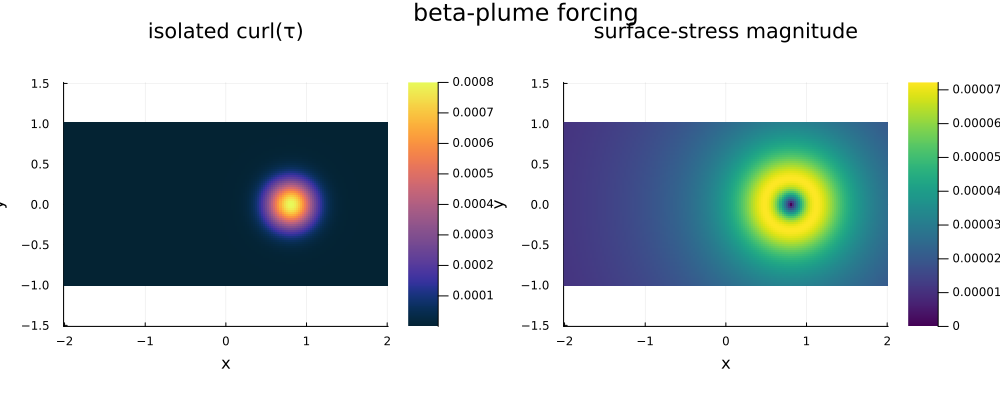

In [3]:
forcing_x = range(-Lx / 2, Lx / 2; length=161)
forcing_y = range(-Ly / 2, Ly / 2; length=81)
curl_field = [wind_curl(xx, yy) for xx in forcing_x, yy in forcing_y]
stress_magnitude = [
    hypot(tau_x(xx, yy), tau_y(xx, yy))
    for xx in forcing_x, yy in forcing_y
]

curl_panel = heatmap(
    forcing_x, forcing_y, curl_field';
    title="isolated curl(τ)", xlabel="x", ylabel="y",
    color=:thermal, aspect_ratio=:equal,
)
stress_panel = heatmap(
    forcing_x, forcing_y, stress_magnitude';
    title="surface-stress magnitude", xlabel="x", ylabel="y",
    color=:viridis, aspect_ratio=:equal,
)
forcing_figure = plot(
    curl_panel, stress_panel;
    layout=(1, 2), size=(1000, 400), plot_title="beta-plume forcing",
)
savefig(forcing_figure, joinpath(@__DIR__, "beta_plume_forcing.png"))
display(forcing_figure)

## Surface-pressure and transport solution

In [4]:
solution = solve_pg(
    problem;
    mesh_file=joinpath(@__DIR__, "beta_plume_pressure.msh"),
    mesh_resolution=0.08,
    pressure_order=2,
    overwrite_mesh=true,
)
display(performance_summary(solution))

┌ Info: PG solve started
│   Ek = 0.003
│   Γ = 0.2
│   viscosity = 1.0
│   diffusivity = 1.0
│   pressure_order = 2
│   mesh_resolution = 0.08
│   mesh_file = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/beta_plume_pressure.msh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:227
┌ Info: Starting generating surface mesh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16


Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000164542s, CPU 0.00015s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.0196851s, CPU 0.019533s)
Info    : 1544 nodes 3090 elements
Info    : Writing '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/beta_plume_pressure.msh'...
Info    : Done writing '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/beta_plume_pressure.msh'
Info    : Reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/Plan

┌ Info: Completed generating surface mesh
│   seconds = 0.064
│   allocated_mib = 3.53
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Starting loading analytical Green-function kernels
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed loading analytical Green-function kernels
│   seconds = 0.0
│   allocated_mib = 0.0
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Surface-pres

(mesh = (seconds = 0.064169958, allocated_mib = 3.531402587890625, gc_seconds = 0.0), kernels = (seconds = 4.2e-8, allocated_mib = 0.0, gc_seconds = 0.0), surface_pressure = (mesh_load = (seconds = 2.767875291, allocated_mib = 620.8105621337891, gc_seconds = 0.119790708), finite_element_setup = (seconds = 3.422639125, allocated_mib = 1757.7958679199219, gc_seconds = 0.252457835), operator_assembly = (seconds = 91.161635875, allocated_mib = 5269.443161010742, gc_seconds = 0.497937207), linear_solve = (seconds = 0.143431833, allocated_mib = 38.611297607421875, gc_seconds = 0.0), total_seconds = 98.50177502632141), total_seconds = 98.6197669506073)

In [5]:
# Stay just inside the finite-element boundary for point evaluation.
x = range(-0.99Lx / 2, 0.99Lx / 2; length=81)
y = range(-0.99Ly / 2, 0.99Ly / 2; length=41)
diagnostics = compute_diagnostics(solution, x, y)
display(performance_summary(diagnostics))

┌ Info: PG diagnostic calculation started
│   Nx = 81
│   Ny = 41
│   horizontal_points = 3321
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1187
┌ Info: Transport streamfunction solve started
│   finite_element_order = 2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:249
┌ Info: Starting constructing streamfunction finite-element spaces
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:12
┌ Info: Completed constructing streamfunction finite-element spaces
│   seconds = 1

(streamfunction = (finite_element_setup = (seconds = 1.185781667, allocated_mib = 497.94020080566406, gc_seconds = 0.04733675), current_projection = (seconds = 30.670946042, allocated_mib = 903.1675567626953, gc_seconds = 0.044672542), operator_assembly = (seconds = 2.897613458, allocated_mib = 364.13743591308594, gc_seconds = 0.018786958), linear_solve = (seconds = 0.00902775, allocated_mib = 11.631805419921875, gc_seconds = 0.0), total_seconds = 34.83674383163452), bottom_stress_projection = (setup = (seconds = 0.090405375, allocated_mib = 15.10406494140625, gc_seconds = 0.0), interpolation = (seconds = 12.824275459, allocated_mib = 9715.029769897461, gc_seconds = 0.398849714), total_seconds = 12.956336975097656), sampling = (seconds = 16.168060917, allocated_mib = 2214.4362182617188, gc_seconds = 0.093912332), total_seconds = 64.43129897117615, wet_points = 3321, points_per_second = 205.40496581801693, transport_projection_relative_l2 = 0.22198930259190222)

## Westward beta plume

The localized forcing drives meridional Sverdrup transport within the patch. Integrating that transport from the eastern boundary produces a streamfunction wake extending westward from the source. Bottom stress closes the circulation near the basin boundaries.

In [ ]:
transport_figure = plot_depth_integrated_current(
    diagnostics;
    arrow_scale=0.36,
    output=joinpath(@__DIR__, "beta_plume_transport.png"),
)
streamfunction_figure = plot_streamfunction(
    diagnostics;
    output=joinpath(@__DIR__, "beta_plume_streamfunction.png"),
)
bottom_stress_figure = plot_bottom_stress(
    diagnostics;
    arrow_scale=0.36,
    output=joinpath(@__DIR__, "beta_plume_bottom_stress.png"),
)
display(transport_figure)
display(streamfunction_figure)
display(bottom_stress_figure)

## Depth-integrated vorticity closure

With flat depth and zero buoyancy, the interior balance is $\beta V=\mathrm{Ek}\,\operatorname{curl}(\tau)$. The bottom-stress curl supplies the departure from Sverdrup balance required to close the plume against the boundaries. For a flat bottom, the barotropic-vorticity balance coincides with this depth-integrated vorticity balance, so only DIV is shown.

In [ ]:
vorticity = compute_vorticity_diagnostics(solution, diagnostics)
display(performance_summary(vorticity))

vorticity_figure = plot_vorticity_balance(
    vorticity;
    output=joinpath(@__DIR__, "beta_plume_vorticity.png"),
)
display(vorticity_figure)

## Surface-pressure equation coefficients

Compute and plot the advection velocity, diffusivity, and separate baroclinic and surface-stress source fields in the surface-pressure equation (74).

In [ ]:
pressure_equation = compute_surface_pressure_equation_diagnostics(
    solution, diagnostics,
)
display(performance_summary(pressure_equation))

pressure_equation_figure = plot_surface_pressure_equation_diagnostics(
    pressure_equation;
    arrow_scale=0.70,
    output=joinpath(@__DIR__, "beta_plume_surface_pressure_equation.png"),
)
display(pressure_equation_figure)

## Sverdrup-plume comparison

In [ ]:
sverdrup_V = [Ek * wind_curl(xx, yy) / beta for xx in x, yy in y]
sverdrup_streamfunction = zeros(length(x), length(y))
for j in eachindex(y), i in (length(x) - 1):-1:1
    dx = x[i + 1] - x[i]
    sverdrup_streamfunction[i, j] =
        sverdrup_streamfunction[i + 1, j] -
        dx * (sverdrup_V[i + 1, j] + sverdrup_V[i, j]) / 2
end

planetary_vorticity = beta .* diagnostics.analytical_transport_V
surface_stress_curl = [Ek * wind_curl(xx, yy) for xx in x, yy in y]
sverdrup_departure = planetary_vorticity .- surface_stress_curl
sverdrup_departure[.!vorticity.wet] .= NaN
interior_scale = maximum(abs, surface_stress_curl)
closure_scale = maximum(abs, [
    sverdrup_departure[vorticity.wet];
    vorticity.bottom_stress_curl[vorticity.wet];
])

p1 = heatmap(x, y, surface_stress_curl';
    title="isolated Ek curl(τ)", xlabel="x", ylabel="y",
    color=:thermal, aspect_ratio=:equal)
p2 = contourf(x, y, sverdrup_streamfunction';
    title="Sverdrup beta plume", xlabel="x", ylabel="y",
    aspect_ratio=:equal)
p3 = contourf(x, y, diagnostics.streamfunction';
    title="PG streamfunction", xlabel="x", ylabel="y",
    aspect_ratio=:equal)
p4 = heatmap(x, y, planetary_vorticity';
    title="βV", xlabel="x", ylabel="y", color=:balance,
    clims=(-interior_scale, interior_scale), aspect_ratio=:equal)
p5 = heatmap(x, y, sverdrup_departure';
    title="βV - Ek curl(τ)", xlabel="x", ylabel="y", color=:balance,
    clims=(-closure_scale, closure_scale), aspect_ratio=:equal)
p6 = heatmap(x, y, vorticity.bottom_stress_curl';
    title="Ek curl(τ_b)", xlabel="x", ylabel="y", color=:balance,
    clims=(-closure_scale, closure_scale), aspect_ratio=:equal)

comparison_figure = plot(
    p1, p2, p3, p4, p5, p6;
    layout=(2, 3), size=(1300, 760),
    plot_title="isolated forcing and westward beta plume",
)
savefig(comparison_figure, joinpath(@__DIR__, "beta_plume_comparison.png"))
display(comparison_figure)

## Plume diagnostics

The shape correlation compares the PG and inviscid Sverdrup streamfunctions west of the forcing while excluding the immediate western boundary current.

In [9]:
westward_plume = [
    xx > -0.8Lx / 2 && xx < forcing_center[1] - 2forcing_radius &&
    abs(yy - forcing_center[2]) < 2forcing_radius
    for xx in x, yy in y
]
eastern_region = [
    xx > forcing_center[1] + 2forcing_radius &&
    abs(yy - forcing_center[2]) < 2forcing_radius
    for xx in x, yy in y
]

westward_peak = maximum(abs, diagnostics.streamfunction[westward_plume])
eastern_peak = maximum(abs, diagnostics.streamfunction[eastern_region])
westward_plume_ratio = westward_peak / eastern_peak
sverdrup_shape_correlation = (
    sum(
        diagnostics.streamfunction[westward_plume] .*
        sverdrup_streamfunction[westward_plume]
    ) /
    sqrt(
        sum(abs2, diagnostics.streamfunction[westward_plume]) *
        sum(abs2, sverdrup_streamfunction[westward_plume])
    )
)

display((;
    maximum_forcing_curl=maximum(curl_field),
    westward_peak,
    eastern_peak,
    westward_plume_ratio,
    sverdrup_shape_correlation,
))

(maximum_forcing_curl = 0.0008, westward_peak = 1.9641888308903037e-6, eastern_peak = 2.567437001870578e-7, westward_plume_ratio = 7.650387641290669, sverdrup_shape_correlation = 0.9016276676805741)